# Predicting Next-Quarter US Real GDP

This demo builds a simple **one-quarter-ahead** forecast of US real GDP using public FRED data.

**Target:** annualized quarter-over-quarter real GDP growth  
**Model:** OLS with lagged macro indicators (a teaching-scale version of a nowcast)  
**Output:** next-quarter growth, the implied GDP level, and an out-of-sample check against a naive forecast

Professional nowcasts such as the Atlanta Fed's GDPNow mix many higher-frequency series as they are released. Here we keep the model small so the steps stay transparent: download data, transform it, respect time order, fit OLS, then forecast one quarter ahead.


In [1]:
import io
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
import statsmodels.api as sm
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.stats.outliers_influence import variance_inflation_factor

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 4)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")


## 1. Download data from FRED

No API key is required. `requests` is used instead of `pandas.read_csv(url)` because some Python.org macOS installs fail FRED's SSL check.

| FRED id | Series | Frequency |
|---|---|---|
| `GDPC1` | Real GDP (chained 2017 dollars, SAAR) | Quarterly |
| `INDPRO` | Industrial production | Monthly |
| `PAYEMS` | Nonfarm payrolls | Monthly |
| `UNRATE` | Unemployment rate | Monthly |
| `HOUST` | Housing starts | Monthly |
| `UMCSENT` | University of Michigan consumer sentiment | Monthly |
| `T10Y2Y` | 10-year minus 2-year Treasury yield | Daily |

These predictors are available *before* the BEA publishes GDP for the same quarter.


In [2]:
def fred(series_id):
    """Download one FRED series and return a pandas Series."""
    url = f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={series_id}"
    response = requests.get(url, timeout=30)
    response.raise_for_status()

    raw = pd.read_csv(io.StringIO(response.text))
    date_col = "observation_date" if "observation_date" in raw.columns else "DATE"
    s = raw.set_index(pd.to_datetime(raw[date_col]))[series_id]
    s = pd.to_numeric(s.replace(".", np.nan), errors="coerce")
    s.name = series_id
    return s.dropna()


series_ids = {
    "gdp": "GDPC1",
    "ip": "INDPRO",
    "emp": "PAYEMS",
    "unrate": "UNRATE",
    "houst": "HOUST",
    "sent": "UMCSENT",
    "curve": "T10Y2Y",
}

raw = {name: fred(sid) for name, sid in series_ids.items()}

availability = pd.DataFrame(
    {
        "series": list(series_ids.keys()),
        "fred_id": list(series_ids.values()),
        "start": [raw[name].index.min().date() for name in series_ids],
        "end": [raw[name].index.max().date() for name in series_ids],
        "n_obs": [raw[name].shape[0] for name in series_ids],
    }
)
availability


,series,fred_id,start,end,n_obs
0,gdp,GDPC1,1947-01-01,2026-04-01,318
1,ip,INDPRO,1919-01-01,2026-07-01,1291
2,emp,PAYEMS,1939-01-01,2026-08-01,1052
3,unrate,UNRATE,1948-01-01,2026-08-01,943
4,houst,HOUST,1959-01-01,2026-07-01,811
5,sent,UMCSENT,1952-11-01,2026-07-01,675
6,curve,T10Y2Y,1976-06-01,2026-09-10,12566


## 2. Real GDP: levels vs growth rates

GDP *levels* trend upward, so they are nonstationary. Forecasting the **annualized log difference** is the standard first step:

\[
g_t = 400 \times \log(GDP_t / GDP_{t-1})
\]

That is approximately the annualized quarter-over-quarter percent change the BEA reports.


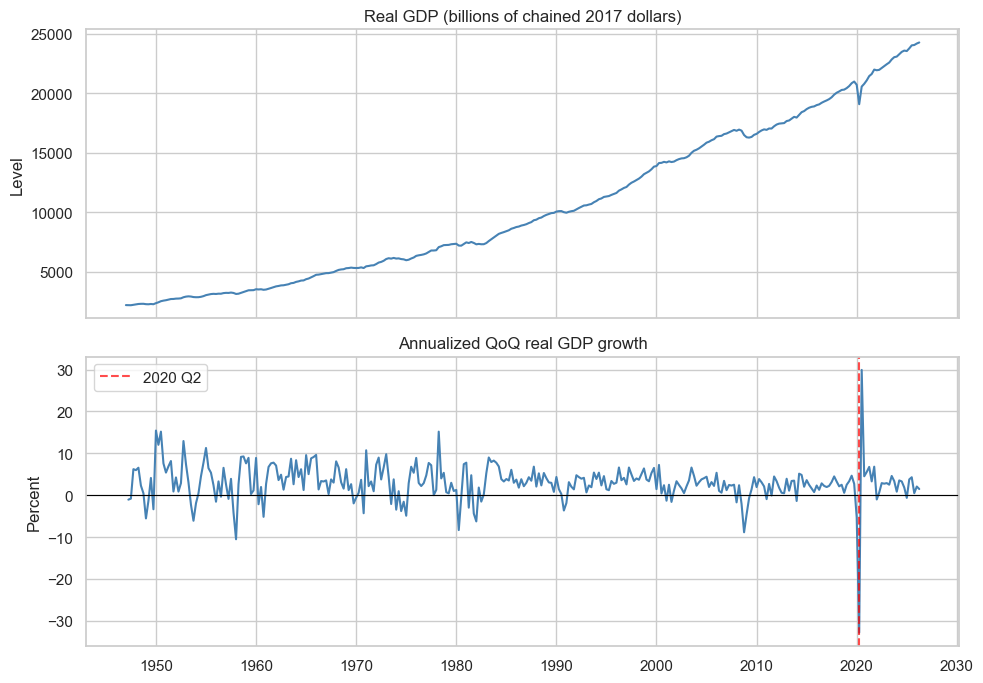

Latest GDP date: 2026-04-01
Latest GDP level: 24269.6
Latest GDP growth: 1.47 percent


,gdp,gdp_growth
observation_date,,
2025-04-01,"23,770.976",3.766
2025-07-01,"24,026.834",4.282
2025-10-01,"24,055.749",0.481
2026-01-01,"24,180.419",2.068
2026-04-01,"24,269.613",1.473


In [3]:
gdp = raw["gdp"].to_frame("gdp")
gdp["gdp_growth"] = 400 * np.log(gdp["gdp"] / gdp["gdp"].shift(1))

fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
axes[0].plot(gdp.index, gdp["gdp"], color="steelblue")
axes[0].set_title("Real GDP (billions of chained 2017 dollars)")
axes[0].set_ylabel("Level")

axes[1].plot(gdp.index, gdp["gdp_growth"], color="steelblue")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].axvline(pd.Timestamp("2020-04-01"), color="red", linestyle="--", alpha=0.7, label="2020 Q2")
axes[1].set_title("Annualized QoQ real GDP growth")
axes[1].set_ylabel("Percent")
axes[1].legend()
plt.tight_layout()
plt.show()

print("Latest GDP date:", gdp["gdp"].dropna().index[-1].date())
print("Latest GDP level:", round(float(gdp["gdp"].dropna().iloc[-1]), 1))
print("Latest GDP growth:", round(float(gdp["gdp_growth"].dropna().iloc[-1]), 2), "percent")
gdp.tail()


## 3. Build a quarterly modeling dataset

Monthly and daily series are collapsed to **quarterly averages**, then converted to growth rates or changes so they line up with GDP.

For a true one-quarter-ahead forecast, every predictor is **lagged one quarter**: we use information known at the end of quarter $t-1$ to predict growth in quarter $t$.


In [4]:
# Collapse higher-frequency series to quarterly means (quarter starts: Jan, Apr, Jul, Oct)
quarterly = pd.DataFrame(
    {
        "gdp": raw["gdp"],
        "ip": raw["ip"].resample("QS").mean(),
        "emp": raw["emp"].resample("QS").mean(),
        "unrate": raw["unrate"].resample("QS").mean(),
        "houst": raw["houst"].resample("QS").mean(),
        "sent": raw["sent"].resample("QS").mean(),
        "curve": raw["curve"].resample("QS").mean(),
    }
)

# Stationary transforms. Unemployment and the yield curve are already in percent / percentage points.
features = pd.DataFrame(index=quarterly.index)
features["gdp_growth"] = 400 * np.log(quarterly["gdp"] / quarterly["gdp"].shift(1))
features["ip_growth"] = 400 * np.log(quarterly["ip"] / quarterly["ip"].shift(1))
features["emp_growth"] = 400 * np.log(quarterly["emp"] / quarterly["emp"].shift(1))
features["d_unrate"] = quarterly["unrate"].diff()
features["houst_growth"] = 400 * np.log(quarterly["houst"] / quarterly["houst"].shift(1))
features["d_sent"] = quarterly["sent"].diff()
features["curve"] = quarterly["curve"]
features["gdp_level"] = quarterly["gdp"]

# Lag all predictors so row t uses only t-1 information.
# Extra columns (emp_growth, houst_growth, d_sent) are stored so you can add them to xcols.
# Do not put emp_growth and d_unrate in the same regression: they are two views of the labor market and inflate VIF.
xcols = ["gdp_growth_lag1", "ip_growth", "d_unrate", "curve"]

model_df = pd.DataFrame({"gdp_growth": features["gdp_growth"]})
model_df["gdp_growth_lag1"] = features["gdp_growth"].shift(1)
model_df["ip_growth"] = features["ip_growth"].shift(1)
model_df["emp_growth"] = features["emp_growth"].shift(1)
model_df["d_unrate"] = features["d_unrate"].shift(1)
model_df["houst_growth"] = features["houst_growth"].shift(1)
model_df["d_sent"] = features["d_sent"].shift(1)
model_df["curve"] = features["curve"].shift(1)

# Sample starts in 1985 so the yield curve and sentiment series are both available
model_df = model_df.dropna().loc["1985-01-01":]

print(model_df.shape)
model_df.tail()


(166, 8)


,gdp_growth,gdp_growth_lag1,ip_growth,emp_growth,d_unrate,houst_growth,d_sent,curve
observation_date,,,,,,,,
2025-04-01,3.766,-0.651,4.145,0.518,0.000,2.490,-7.633,0.305
2025-07-01,4.282,3.766,1.806,0.426,0.067,-11.820,-9.433,0.500
2025-10-01,0.481,4.282,2.122,0.085,0.133,-2.565,3.300,0.540
2026-01-01,2.068,0.481,-1.890,-0.230,0.117,-7.189,-5.833,0.578
2026-04-01,1.473,2.068,1.250,0.327,-0.117,27.543,2.933,0.617


       gdp_growth  gdp_growth_lag1  ip_growth  d_unrate   curve
count     166.000          166.000    166.000   166.000 166.000
mean        2.580            2.590      1.500    -0.020   0.980
std         4.160            4.160      6.790     0.850   0.870
min       -32.820          -32.820    -53.750    -4.200  -0.770
25%         1.600            1.660     -0.060    -0.190   0.260
50%         2.850            2.880      2.190    -0.070   0.870
75%         3.930            3.930      4.190     0.070   1.640
max        29.900           29.900     36.210     9.170   2.800


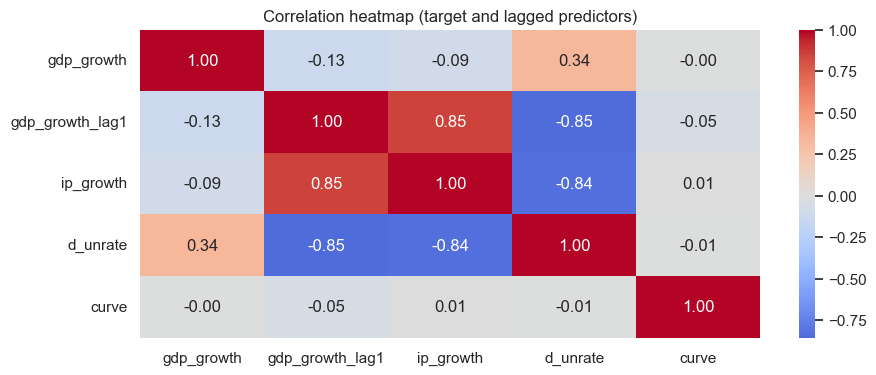

In [5]:
print(model_df[["gdp_growth"] + xcols].describe().round(2))

# Same idea as the Airbnb demo: look at linear association before fitting
sns.heatmap(
    model_df[["gdp_growth"] + xcols].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
)
plt.title("Correlation heatmap (target and lagged predictors)")
plt.show()


## 4. Time-series train / test split

Do **not** use `train_test_split` with a random shuffle. That would leak future GDP into the training set.

Hold out the last 12 quarters as a pseudo out-of-sample evaluation window, and train on everything before that.


In [6]:
test_n = 12
train = model_df.iloc[:-test_n]
test = model_df.iloc[-test_n:]

print("Train:", train.index.min().date(), "to", train.index.max().date(), f"({len(train)} quarters)")
print("Test: ", test.index.min().date(), "to", test.index.max().date(), f"({len(test)} quarters)")

y = "gdp_growth"
X_train = sm.add_constant(train[xcols])
X_test = sm.add_constant(test[xcols])


Train: 1985-01-01 to 2023-04-01 (154 quarters)
Test:  2023-07-01 to 2026-04-01 (12 quarters)


## 5. OLS forecast model

Newey-West (HAC) standard errors are used because growth residuals are often serially correlated.

A one-quarter lag of industrial production is the most direct activity signal here. Lagged unemployment can have the "wrong" sign: after a recession, unemployment is still high while growth rebounds. That is a reason to treat this as a forecast, not a structural model.



In [7]:
# OLS is appropriate because the outcome is continuous growth, not a 0/1 outcome
model = sm.OLS(train[y], X_train).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
print(model.summary())


                            OLS Regression Results                            
Dep. Variable:             gdp_growth   R-squared:                       0.273
Model:                            OLS   Adj. R-squared:                  0.253
Method:                 Least Squares   F-statistic:                     5.023
Date:                Thu, 10 Sep 2026   Prob (F-statistic):           0.000796
Time:                        20:07:43   Log-Likelihood:                -418.20
No. Observations:                 154   AIC:                             846.4
Df Residuals:                     149   BIC:                             861.6
Df Model:                           4                                         
Covariance Type:                  HAC                                         
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
const               1.1263      1.273     

In [8]:
## Post regression
# 1. Residual analysis
# 2. Multicollinearity (VIF > 10 is a warning)
# 3. Out-of-sample fit vs a naive forecast


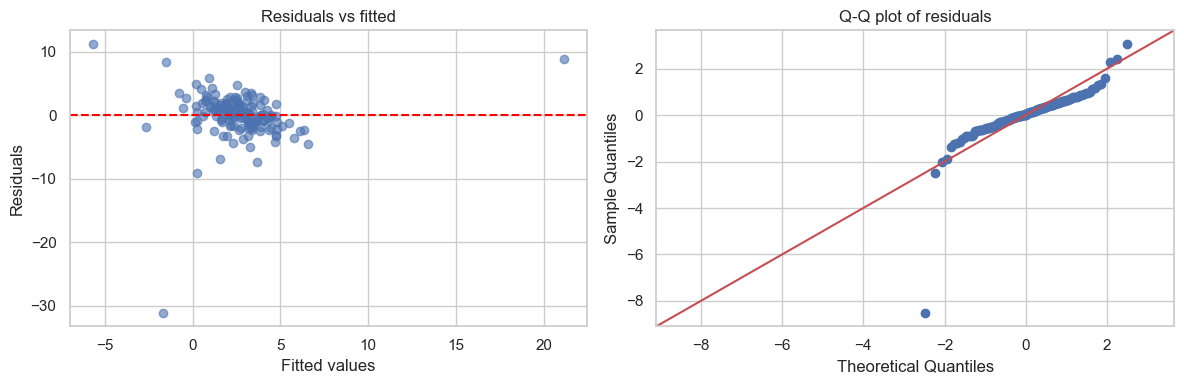

R-squared: 0.273
Adj. R-squared: 0.253
AIC: 846.4


,feature,VIF
0,const,4.202
1,gdp_growth_lag1,5.236
2,ip_growth,4.550
3,d_unrate,4.519
4,curve,1.009


In [9]:
fitted = model.fittedvalues
resid = model.resid

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(fitted, resid, alpha=0.6)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_xlabel("Fitted values")
axes[0].set_ylabel("Residuals")
axes[0].set_title("Residuals vs fitted")

sm.qqplot(resid, line="45", fit=True, ax=axes[1])
axes[1].set_title("Q-Q plot of residuals")
plt.tight_layout()
plt.show()

print("R-squared:", round(model.rsquared, 3))
print("Adj. R-squared:", round(model.rsquared_adj, 3))
print("AIC:", round(model.aic, 1))

vif = pd.DataFrame({"feature": X_train.columns})
vif["VIF"] = [variance_inflation_factor(X_train.values, i) for i in range(X_train.shape[1])]
vif


Out-of-sample accuracy, last 12 quarters (percentage points)
                                MAE  RMSE
OLS                           1.510 1.840
Naive (last quarter's growth) 1.970 2.330


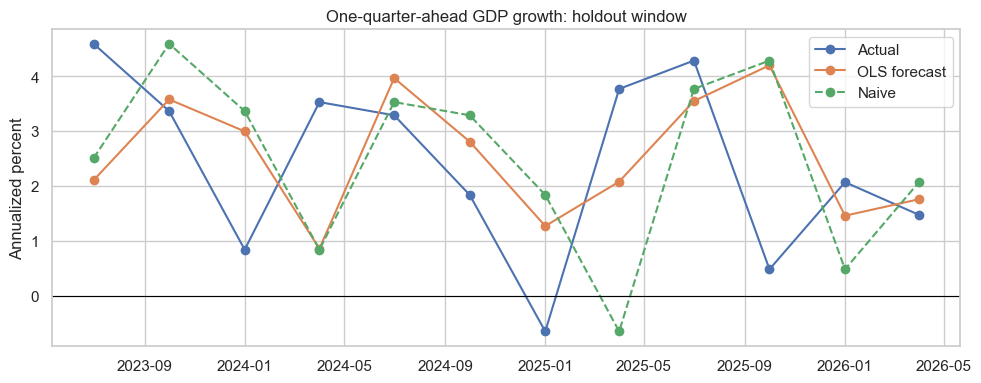

,actual,ols,naive
observation_date,,,
2023-07-01,4.590,2.100,2.500
2023-10-01,3.360,3.570,4.590
2024-01-01,0.840,2.990,3.360
2024-04-01,3.530,0.860,0.840
2024-07-01,3.290,3.960,3.530
2024-10-01,1.840,2.810,3.290
2025-01-01,-0.650,1.270,1.840
2025-04-01,3.770,2.080,-0.650
2025-07-01,4.280,3.550,3.770


In [10]:
# Out-of-sample: OLS vs a naive "growth stays at last quarter's value" forecast
pred_ols = model.predict(X_test)
pred_naive = test["gdp_growth_lag1"]

oos = pd.DataFrame(
    {
        "actual": test[y],
        "ols": pred_ols,
        "naive": pred_naive,
    }
)

def rmse(a, p):
    return float(np.sqrt(mean_squared_error(a, p)))

metrics = pd.DataFrame(
    {
        "MAE": [
            mean_absolute_error(oos["actual"], oos["ols"]),
            mean_absolute_error(oos["actual"], oos["naive"]),
        ],
        "RMSE": [
            rmse(oos["actual"], oos["ols"]),
            rmse(oos["actual"], oos["naive"]),
        ],
    },
    index=["OLS", "Naive (last quarter's growth)"],
)

print("Out-of-sample accuracy, last 12 quarters (percentage points)")
print(metrics.round(2))

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(oos.index, oos["actual"], marker="o", label="Actual")
ax.plot(oos.index, oos["ols"], marker="o", label="OLS forecast")
ax.plot(oos.index, oos["naive"], marker="o", linestyle="--", label="Naive")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("One-quarter-ahead GDP growth: holdout window")
ax.set_ylabel("Annualized percent")
ax.legend()
plt.tight_layout()
plt.show()

oos.round(2)


## 6. Forecast the next quarter

Refit on the full sample, then plug in the **latest complete quarter** of predictors (the same information set we would have had at the end of the last published GDP quarter).

The implied GDP *level* is recovered by reversing the log-difference:

\[
\widehat{GDP}_{T+1} = GDP_T \times \exp(\hat g_{T+1} / 400)
\]


In [11]:
full_model = sm.OLS(model_df[y], sm.add_constant(model_df[xcols])).fit(
    cov_type="HAC", cov_kwds={"maxlags": 4}
)

last_gdp_date = features["gdp_level"].dropna().index[-1]
last_gdp = float(features.loc[last_gdp_date, "gdp_level"])
next_quarter = last_gdp_date + pd.DateOffset(months=3)

# Predictors dated last_gdp_date (not lagged) forecast growth in the following quarter
x_next = pd.DataFrame(
    {
        "gdp_growth_lag1": features.loc[last_gdp_date, "gdp_growth"],
        "ip_growth": features.loc[last_gdp_date, "ip_growth"],
        "d_unrate": features.loc[last_gdp_date, "d_unrate"],
        "curve": features.loc[last_gdp_date, "curve"],
    },
    index=[next_quarter],
)

pred_growth = float(full_model.predict(sm.add_constant(x_next, has_constant="add")).iloc[0])
pred_level = last_gdp * np.exp(pred_growth / 400)
pred_interval = full_model.get_prediction(sm.add_constant(x_next, has_constant="add")).summary_frame(alpha=0.10)

print(f"Latest published GDP: {last_gdp_date.date()} (quarter start)")
print(f"Latest GDP level:     {last_gdp:,.1f} billion chained 2017 dollars")
print(f"Forecast quarter:     {next_quarter.date()} (quarter start)")
print()
print(f"Predicted annualized growth: {pred_growth:.2f} percent")
print(f"90% interval:                {pred_interval['obs_ci_lower'].iloc[0]:.2f} to {pred_interval['obs_ci_upper'].iloc[0]:.2f}")
print(f"Implied real GDP level:     {pred_level:,.1f}")

forecast_table = x_next.copy()
forecast_table["predicted_growth"] = pred_growth
forecast_table["implied_gdp"] = pred_level
forecast_table.round(3)


Latest published GDP: 2026-04-01 (quarter start)
Latest GDP level:     24,269.6 billion chained 2017 dollars
Forecast quarter:     2026-07-01 (quarter start)

Predicted annualized growth: 2.63 percent
90% interval:                -3.41 to 8.68
Implied real GDP level:     24,429.9


,gdp_growth_lag1,ip_growth,d_unrate,curve,predicted_growth,implied_gdp
2026-07-01,1.473,4.073,-0.067,0.456,2.633,"24,429.904"


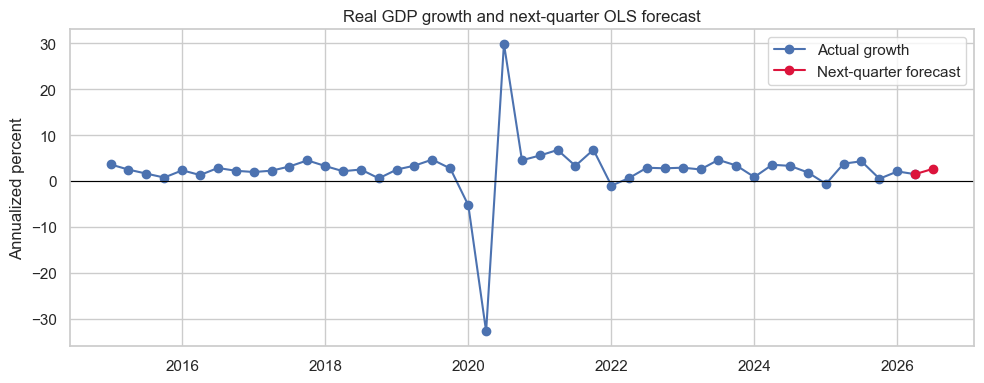

In [12]:
# History plus the one-step forecast
fig, ax = plt.subplots(figsize=(10, 4))
recent = features.loc["2015-01-01":, "gdp_growth"].dropna()
ax.plot(recent.index, recent, marker="o", label="Actual growth")
ax.plot(
    [last_gdp_date, next_quarter],
    [features.loc[last_gdp_date, "gdp_growth"], pred_growth],
    color="crimson",
    marker="o",
    label="Next-quarter forecast",
)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Real GDP growth and next-quarter OLS forecast")
ax.set_ylabel("Annualized percent")
ax.legend()
plt.tight_layout()
plt.show()


## Caveats for class discussion

1. **Revised data, not a real-time vintage.** FRED's current `GDPC1` includes later BEA revisions. A true nowcast would use the data as it stood at each forecast date.
2. **Small, lag-only information set.** GDPNow updates as payrolls, industrial production, and retail sales arrive *during* the quarter. This notebook waits until the previous quarter is complete.
3. **Linear OLS and outliers.** COVID 2020 Q2 is a huge outlier. A dummy for that quarter, a robust estimator, or a shorter sample are natural extensions. Try adding `emp_growth`, `houst_growth`, or `d_sent` to `xcols` and compare OOS RMSE.
4. **This is a baseline.** Adding more timely monthly series, MIDAS, or a factor model is the next step if you want to move toward a production nowcast.

